The goal in this notebook is start to build the baseline models to see how accurately simple algorithms can classify stars vs quasars using color features.

In [37]:
# starting and loading

import pandas as pd
from pathlib import Path 

proj_root = Path.cwd().parent
features_path = proj_root/"data"/"processed"/"sdss_features.csv"

colors = ['u_g','g_r','r_i','i_z']
df = pd.read_csv(features_path)
X = df[colors]
y = df['target']

print(X.shape)
print(y.shape)

(99958, 4)
(99958,)


In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=13, stratify=y)

In [39]:
print(y.value_counts(normalize=True))
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

target
0    0.50017
1    0.49983
Name: proportion, dtype: float64
target
0    0.500175
1    0.499825
Name: proportion, dtype: float64
target
0    0.50015
1    0.49985
Name: proportion, dtype: float64


Since the dataset is balanced 50/50, stratify=y maintains a precise balance between both targets, but in this case, if it didn't exist, wouldn't really make a big difference. stratify=y is a good practice nonetheless, because if the dataset wasn't balanced or if I wanted to only check z > 6 high-redshift quasars, a random unstratified split could cause me problems.

In [40]:
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier(strategy='most_frequent')
print(dummy_clf.fit(X_train, y_train))

print(dummy_clf.score(X_test, y_test))

DummyClassifier(strategy='most_frequent')
0.5001500600240096


baseline is exactly y_test proportion with the dummyclassifier

## Logistic Regression

In [41]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(random_state=13))
])

lr_pipe.fit(X_train, y_train)

train_acc = lr_pipe.score(X_train, y_train)
test_acc = lr_pipe.score(X_test, y_test)

print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

lr_clf = lr_pipe

Train Accuracy: 0.9151
Test Accuracy: 0.9131


In [42]:
for color, weight in zip(colors, lr_pipe.named_steps['classifier'].coef_[0]):
    print(f"{color}: {weight:.3f}")
print(f"bias {lr_pipe.named_steps['classifier'].intercept_[0]:.3f}")

u_g: -3.380
g_r: -0.031
r_i: 0.513
i_z: 0.403
bias -0.391


The accuracy with LogisticRegression jumped to 91.3%. u-g's strong negative weight causes the model to fall a lot more towards 0 (star) then 1 (qso), since stars have higher u-g color. example: u-g = 1.5 x -4.279 = -6.42, which is a massive penalty compared to u-g = 0.2 x -4.279 = -0.85.

## Gaussian Naive Bayes

In [43]:
from sklearn.naive_bayes import GaussianNB

gnb_clf = GaussianNB()
gnb_clf.fit(X_train, y_train)
gnb_clf.score(X_test, y_test)

0.7273409363745498

72% accuracy. gaussian naive bayes assumes the features are independent and that they form a bell curve. gnb doesn't accomodate our needs here because of those characteristics

## Random Forest Pipeline

In [44]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline([
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=13))
])

rf_pipe.fit(X_train, y_train)

train_acc = rf_pipe.score(X_train, y_train)
test_acc = rf_pipe.score(X_test, y_test)

print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Train Accuracy: 1.0000
Test Accuracy: 0.9572


## Confusion Matrix

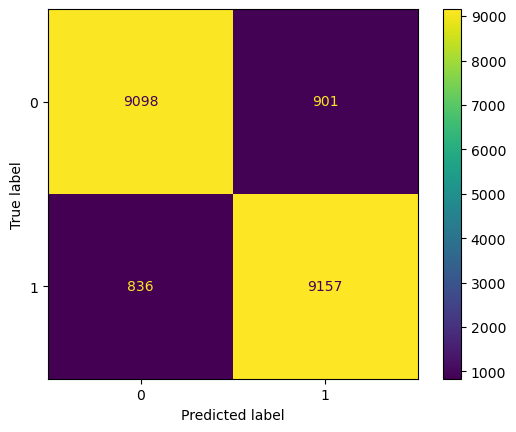

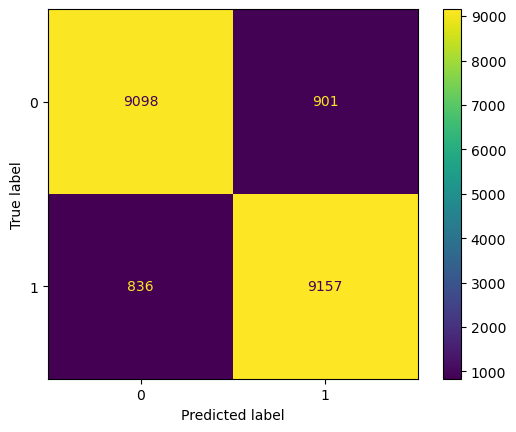

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay.from_estimator(lr_clf, X_test, y_test)
disp.figure_.savefig(proj_root / "reports" / "figures" / "confusion_matrix_baseline.png", dpi=300, bbox_inches="tight")

The model is more prone to wrongly classify stars as quasars. Those stars are probably emmit a lot of ultraviolet light, like white dwarfs or a/b stars

In [52]:
from sklearn.metrics import classification_report

y_pred = lr_clf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=['STAR', 'QSO']))

y_pred = rf_pipe.predict(X_test)
print(classification_report(y_test, y_pred, target_names=['STAR', 'QSO']))

              precision    recall  f1-score   support

        STAR       0.92      0.91      0.91      9999
         QSO       0.91      0.92      0.91      9993

    accuracy                           0.91     19992
   macro avg       0.91      0.91      0.91     19992
weighted avg       0.91      0.91      0.91     19992

              precision    recall  f1-score   support

        STAR       0.96      0.96      0.96      9999
         QSO       0.96      0.96      0.96      9993

    accuracy                           0.96     19992
   macro avg       0.96      0.96      0.96     19992
weighted avg       0.96      0.96      0.96     19992



## Roc Curve

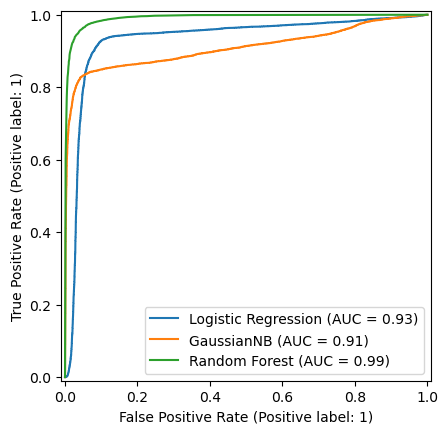

In [51]:
from sklearn.metrics import RocCurveDisplay

ax = RocCurveDisplay.from_estimator(lr_clf, X_test, y_test, name='Logistic Regression').ax_
RocCurveDisplay.from_estimator(gnb_clf, X_test, y_test, ax=ax)
RocCurveDisplay.from_estimator(rf_pipe, X_test, y_test, ax=ax, name='Random Forest')

ax.figure.savefig(proj_root / "reports" / "figures" / "roc_curves_baseline.png", dpi=300, bbox_inches="tight")

## Save Model Artifacts

In [48]:
import joblib

models_dir = proj_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(lr_pipe, models_dir / "logistic_regression_pipeline.joblib")
joblib.dump(rf_pipe, models_dir / "random_forest_pipeline.joblib")

['/home/blajasp/dev/projs/sdss-quasar-classification/models/random_forest_pipeline.joblib']